In [109]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from mlxtend.plotting import plot_decision_regions

In [110]:
df = pd.read_csv('../datasets/polynomial_classification_dataset.csv')
df.head()

,X1,X2,output
0,-1.254599,1.420316,0
1,4.507143,-4.158600,1
2,2.319939,-3.383713,1
3,0.986585,3.985542,1
4,-3.439814,1.064291,1


In [111]:
df.isnull().sum()

X1        0
X2        0
output    0
dtype: int64

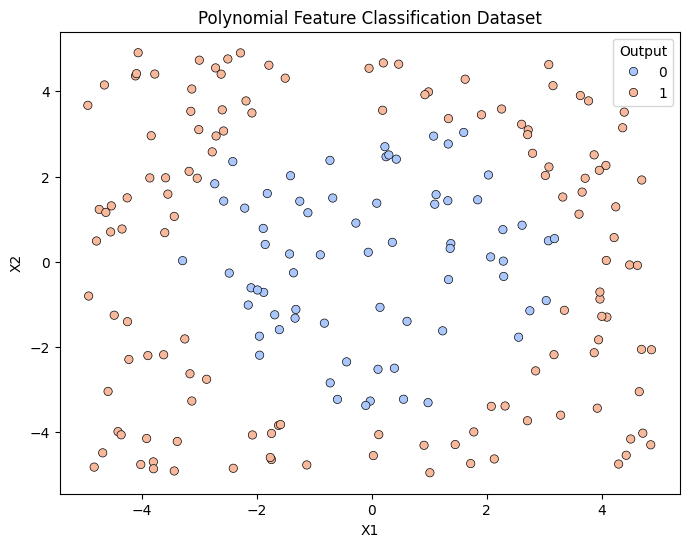

In [112]:
plt.figure(figsize=(8, 6))
scatter = sns.scatterplot(data=df, x="X1", y="X2", hue="output", palette="coolwarm", edgecolor="k")

plt.title("Polynomial Feature Classification Dataset")
plt.xlabel("X1")
plt.ylabel("X2")

plt.legend(title="Output")

plt.show()

In [113]:
x = df.iloc[:, :-1]
y = df['output']

x.ndim, y.ndim

(2, 1)

In [114]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## Implementing Logistic Regression without Polynomial Featuring

In [115]:
lr = LogisticRegression()
lr.fit(x_train, y_train)

LogisticRegression()

In [116]:
lr.score(x_test, y_test)

0.675

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


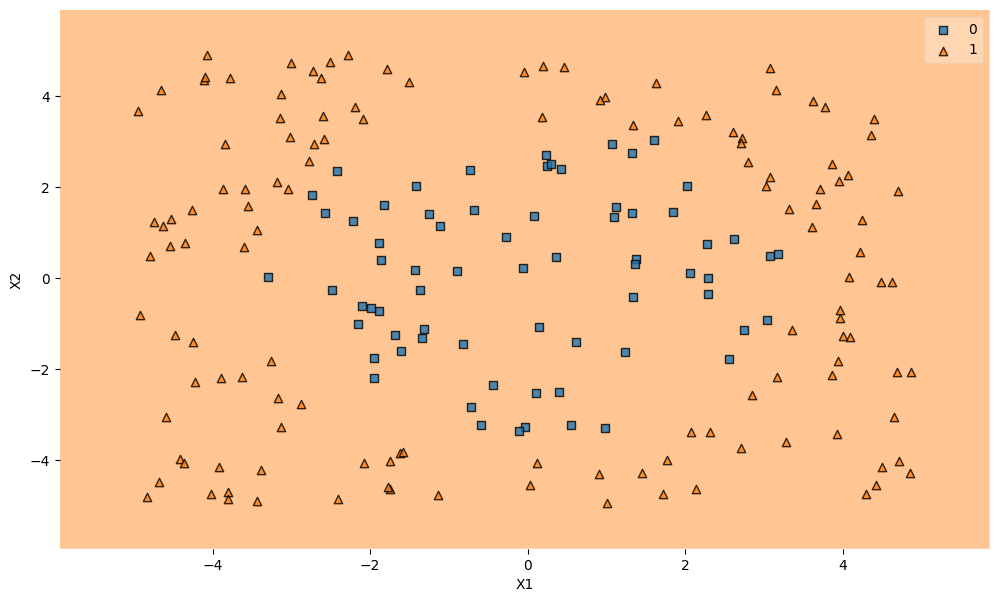

In [117]:
plt.figure(figsize=(12,7))
plot_decision_regions(x.to_numpy(), y.to_numpy(), clf=lr)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

We can see that our logistic regression directly cannot classify this dataset fileds

---

## Implementing Logistic Regression with Polynomial Featuring

In [118]:
df = pd.read_csv('../datasets/polynomial_classification_dataset.csv')
df.head()

,X1,X2,output
0,-1.254599,1.420316,0
1,4.507143,-4.158600,1
2,2.319939,-3.383713,1
3,0.986585,3.985542,1
4,-3.439814,1.064291,1


In [119]:
x = df.iloc[:, :-1]
y = df['output']

x.ndim, y.ndim

(2, 1)

In [120]:
from sklearn.preprocessing import PolynomialFeatures

In [121]:
pf = PolynomialFeatures(degree=2)
pf.fit(x)
pf.transform(x)

array([[  1.        ,  -1.25459881,   1.42031646,   1.57401818,
         -1.78192734,   2.01729885],
       [  1.        ,   4.50714306,  -4.15860035,  20.3143386 ,
        -18.74340672,  17.29395687],
       [  1.        ,   2.31993942,  -3.38371286,   5.3821189 ,
         -7.85000884,  11.44951271],
       ...,
       [  1.        ,   3.9711026 ,  -0.71005973,  15.76965586,
         -2.81972002,   0.50418481],
       [  1.        ,   3.87086424,   2.50871068,  14.98358999,
          9.71087846,   6.29362927],
       [  1.        ,   2.79875546,   2.54542874,   7.83303212,
          7.12403258,   6.47920747]])

In [122]:
x = pd.DataFrame(pf.transform(x))
x

,0,1,2,3,4,5
0,1.0,-1.254599,1.420316,1.574018,-1.781927,2.017299
1,1.0,4.507143,-4.158600,20.314339,-18.743407,17.293957
2,1.0,2.319939,-3.383713,5.382119,-7.850009,11.449513
3,1.0,0.986585,3.985542,0.973350,3.932075,15.884544
4,1.0,-3.439814,1.064291,11.832318,-3.660961,1.132714
...,...,...,...,...,...,...
195,1.0,-1.507904,4.307573,2.273775,-6.495408,18.555187
196,1.0,2.259557,3.584128,5.105597,8.098540,12.845970
197,1.0,3.971103,-0.710060,15.769656,-2.819720,0.504185
198,1.0,3.870864,2.508711,14.983590,9.710878,6.293629


In [127]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [128]:
lr = LogisticRegression()
lr.fit(x_train, y_train)

LogisticRegression()

In [129]:
lr.score(x_test, y_test)

0.975

We can see that the model performance is increased as we use polynomial featuring

---